In [25]:
using QuantumOptics, Plots

# setup Spin, Fock and combined basis

In [26]:
ħ = 1;
δ = 0.1; #detuning ωa - ω\_osz.
g = 1; #kopplungsstärke
ωa = 25; #atomare frequenz
nf = 24; # cutoff Fock basis

In [27]:
basis_spin = SpinBasis(1//2); #d.h. paulimatrizen funktionieren. in n level basis müsste man umrechnungen einführen

basis_fock = FockBasis(nf);

basis = basis_fock ⊗ basis_spin

[Fock(cutoff=24) ⊗ Spin(1/2)]

# simple two level atom driven by laser (task 1)

In [28]:
σ⁺ = sigmam(basis_spin); #absorbtion
σ⁻ = sigmap(basis_spin); #emission
σz = sigmaz(basis_spin);

In [29]:
function H_a(δ, g)
    return (ħ*δ/2)*σz + ħ*g*(σ⁺+σ⁻); # Hamiltonian for two level atom driven by laser (in rotating frame)
end

t = 0:0.1:10;

ψg = spindown(basis_spin); #ground state

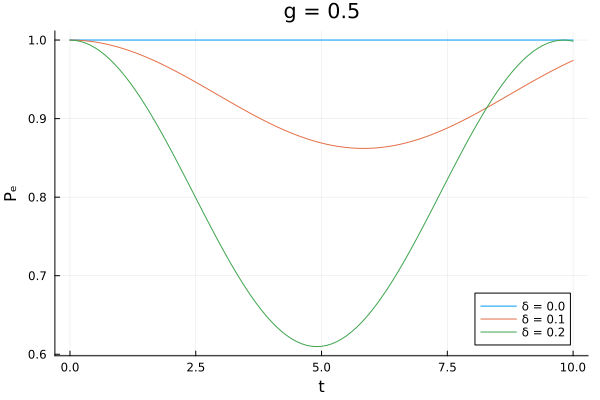

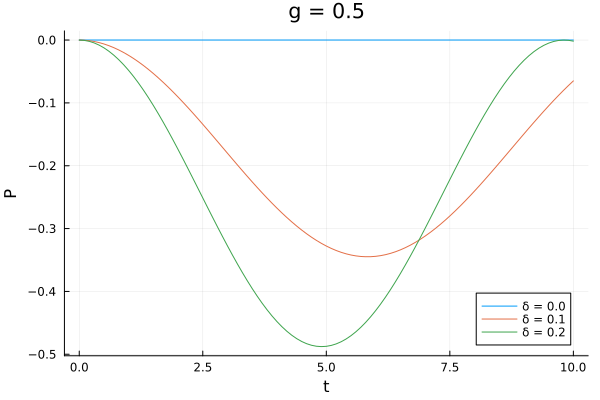

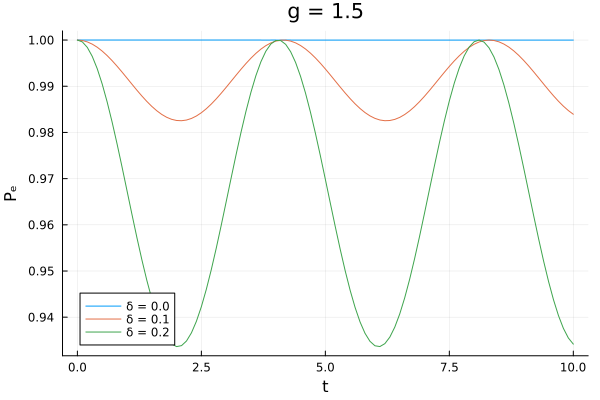

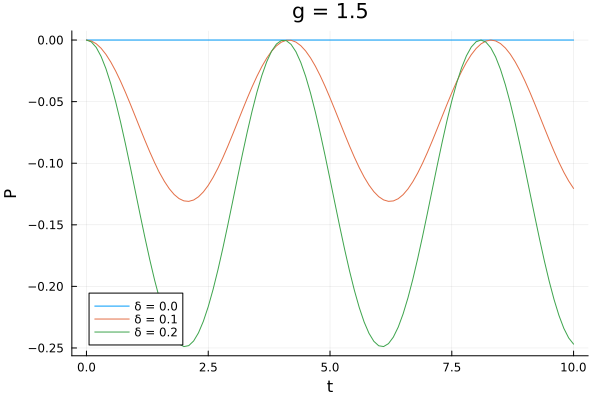

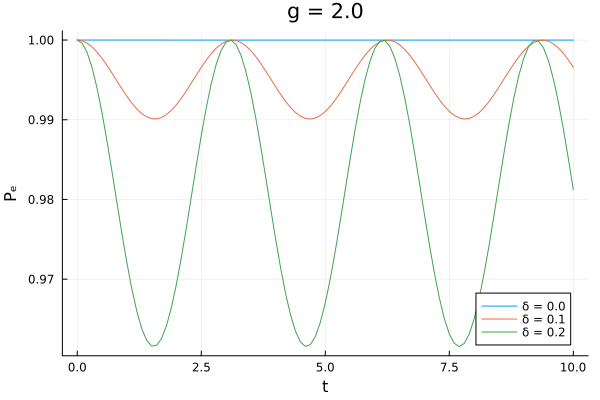

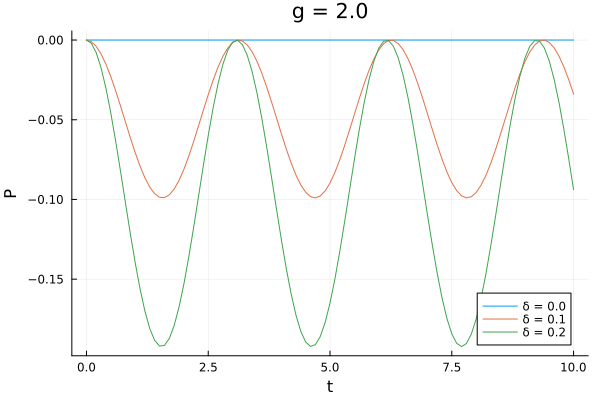

In [30]:

g = [0.5, 1.5, 2];
δ = [0, 0.1, 0.2];

for i in g
    plt = plot(title="g = $i", xlabel="t", ylabel="Pₑ")
    plt2 = plot(title="g = $i", xlabel="t", ylabel="P")
    for j in δ
        H = H_a(i, j);
        tout, ψt = timeevolution.schroedinger(t, ψg, H);
        
        P_e = real.(expect(σ⁺*σ⁻, ψt)); #atomic population
        P = real.(expect(σ⁻, ψt)); #polarisation
        
        plot!(plt, tout, P_e, label="δ = $j");
        plot!(plt2, tout, P, label="δ = $j");
    end
    display(plt)
    display(plt2)
end


# Coupled system

In [31]:
#atomic operators
δ = 0.1;
g = 1;
σ⁺ = one(basis_fock) ⊗ sigmam(basis_spin); #wegen definitionsunerschieden zw mathematischer und physikalischer definition gegengleich
σ⁻ = one(basis_fock) ⊗ sigmap(basis_spin);
σz = one(basis_fock) ⊗ sigmaz(basis_spin);
#field operators
a = destroy(basis_fock) ⊗ one(basis_spin);
a⁺ = dagger(a);
N = a⁺*a;

In [32]:
Hs = ħ*(ωa+δ)*σ⁺*σ⁻; #hamiltonian for atom
Hf = ħ*ωa*(N + 1/2*one(basis)); #hamiltonian for field
Hw = ħ*g*(a⁺*σ⁻ + a*σ⁺); #coupling (excuse my english)

H_ges = Hs+Hf+Hw;

# Eigenstates

[ Info: Defaulting to sparse diagonalization for sparse operator. If storing the full operator is possible, it might be faster to do `eigenstates(dense(op))`. Set `info=false` to turn off this message.


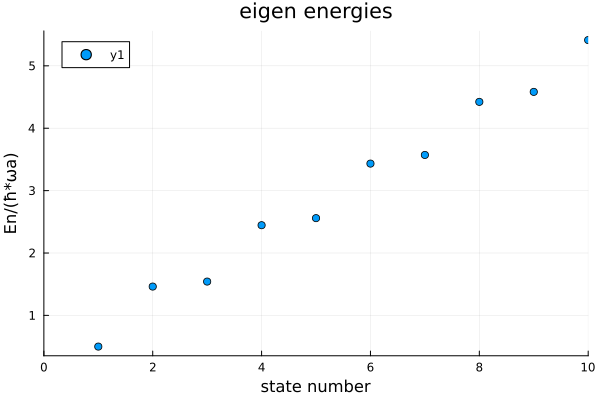

In [33]:
En, ϕn = eigenstates(H_ges, 10);
scatter(En/(ħ*ωa), xlims=(0,10), xlabel="state number", ylabel="En/(ħ*ωa)", title="eigen energies")

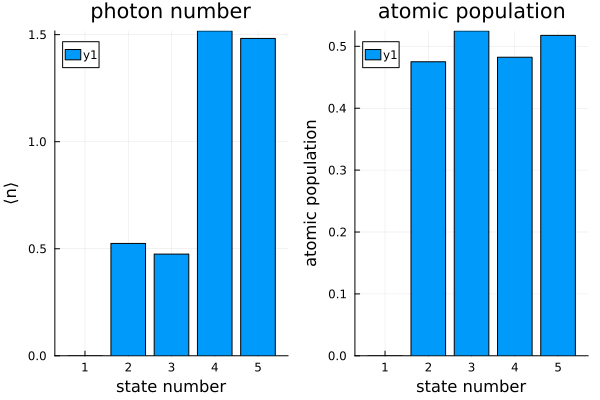

In [34]:
E5 = En[1:5];
ϕ5 = ϕn[1:5];

P_N = [real.(expect(N, ϕ) for ϕ in ϕ5)];
P_ap = [real.(expect(σ⁺*σ⁻, ϕ) for ϕ in ϕ5)];

Plot_N = bar(1:5, P_N, xlabel="state number", ylabel="⟨n⟩", title="photon number");
Plot_ap = bar(1:5, P_ap, xlabel="state number", ylabel="atomic population", title="atomic population");

plot(Plot_N, Plot_ap)

# task 4

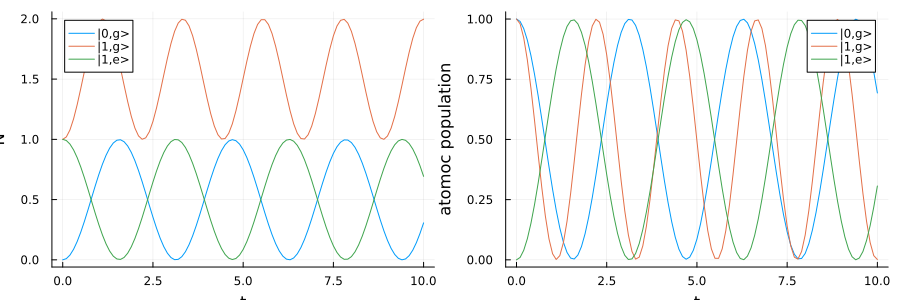

In [35]:
#solution with states as in lecture
δ = 0;
ψ0 = basisstate(basis_fock, 1) ⊗ basisstate(basis_spin, 2); tout, ψ0t = timeevolution.schroedinger(t, ψ0, H_ges);
ψ1 = basisstate(basis_fock, 2) ⊗ basisstate(basis_spin, 2); tout1, ψ1t = timeevolution.schroedinger(t, ψ1, H_ges);
ψ2 = basisstate(basis_fock, 2) ⊗ basisstate(basis_spin, 1); tout2, ψ2t = timeevolution.schroedinger(t, ψ2, H_ges);


p_ph = plot(xlabel = "t", ylabel = "N", title = ""); p_ph = plot!(tout, real.(expect(N, ψ0t)), label = "|0,g>");
p_ph = plot!(tout1, real.(expect(N, ψ1t)), label = "|1,g>"); p_ph = plot!(tout2, real.(expect(N, ψ2t)), label = "|1,e>");

p_pop = plot(xlabel = "t", ylabel = "atomoc population", title = ""); p_pop=plot!(tout, real.(expect(σ⁺*σ⁻, ψ0t)), label = "|0,g>");
p_pop=plot!(tout1, real.(expect(σ⁺*σ⁻, ψ1t)), label = "|1,g>"); p_pop=plot!(tout2, real.(expect(σ⁺*σ⁻, ψ2t)), label = "|1,e>");

plot(p_ph, p_pop, size=(900,300))

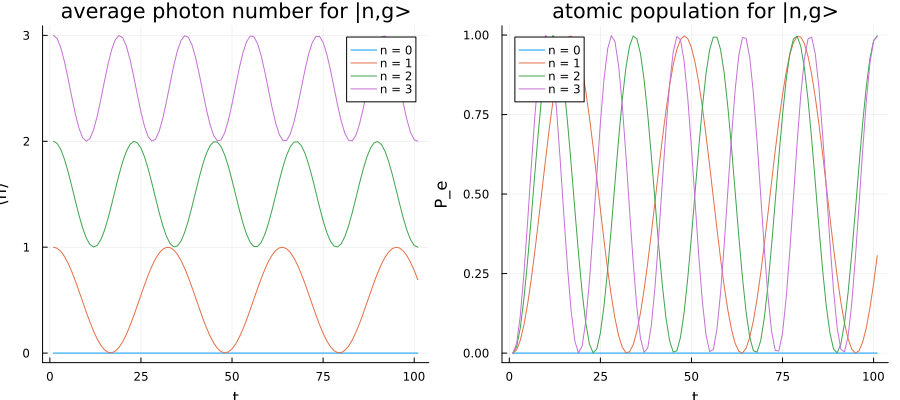

In [36]:
ψ_0(n) = basisstate(basis_fock, n+1) ⊗ basisstate(basis_spin, 1); # |n,g>

P_ph = plot(xlabel="t", ylabel="⟨n⟩", title="average photon number for |n,g>"); # photon number
P_ap = plot(xlabel="t", ylabel="P_e", title="atomic population for |n,g>"); # atomic population

for i in 0:3
    tout, ψt = timeevolution.schroedinger(t, ψ_0(i), H_ges);

    P_N = real.(expect(N, ψt));
    P_e = real.(expect(σ⁺*σ⁻, ψt));

    plot!(P_ph, P_N, label="n = $i");
    plot!(P_ap, P_e, label="n = $i");
end

plot(P_ph, P_ap, size=(900,400))

# task 5: coherent state

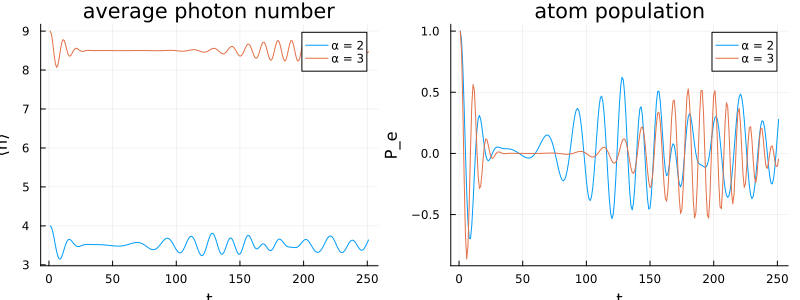

In [37]:
ψa(α) = coherentstate(basis_fock, α) ⊗ basisstate(basis_spin,1);

t2 = 0:0.1:25;
a = [2,3];

P_ph = plot(xlabel="t", ylabel="⟨n⟩", title="average photon number"); # photon number
P_ap = plot(xlabel="t", ylabel="P_e", title="atom population"); # atom population

for i in a
    tout, ψat = timeevolution.schroedinger(t2, ψa(i), H_ges);

    P_N = real.(expect(N, ψat));
    P_e = real.(expect(σz, ψat));

    plot!(P_ph, P_N, label="α = $i");
    plot!(P_ap, P_e, label="α = $i");
end

plot(P_ph, P_ap, size=(800,300))

# task 6: heatmap

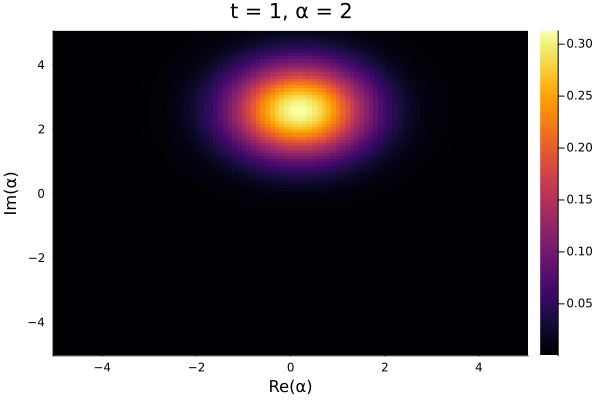

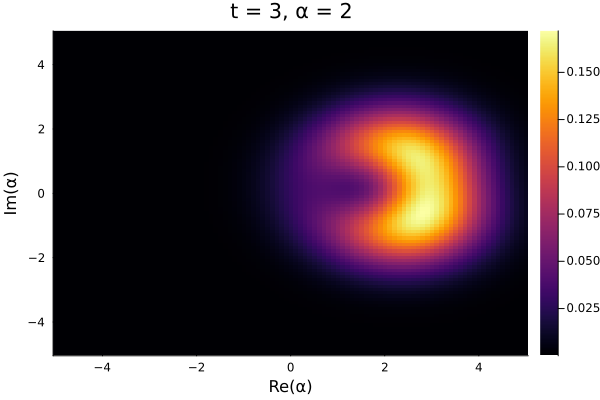

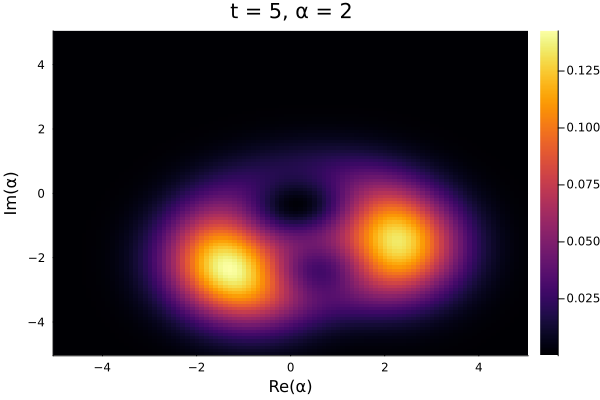

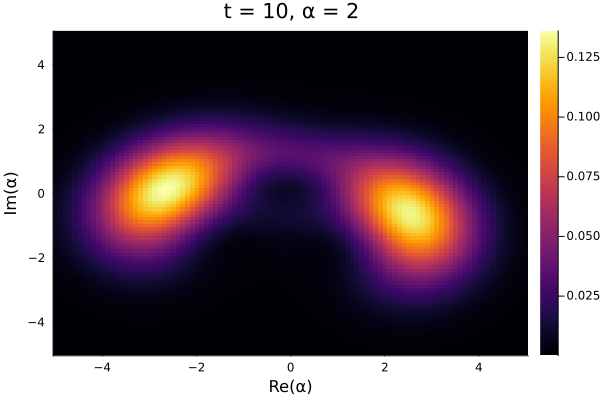

In [38]:
points = -5:0.1:5;
t = [1, 3, 5, 10];

tout, ψat = timeevolution.schroedinger(t2, ψa(2), H_ges);
heatPlots = [];

for j in t
    p_field = ptrace(ψat[Int(6*j)], 2);
    Qf = qfunc(p_field, points, points);
    heatMap = heatmap(points, points, real.(Qf), xlabel="Re(α)", ylabel="Im(α)", title="t = $j, α = 2");
    push!(heatPlots, heatMap);
end

for i in 1:4
    display(heatPlots[i])
end


# task 7

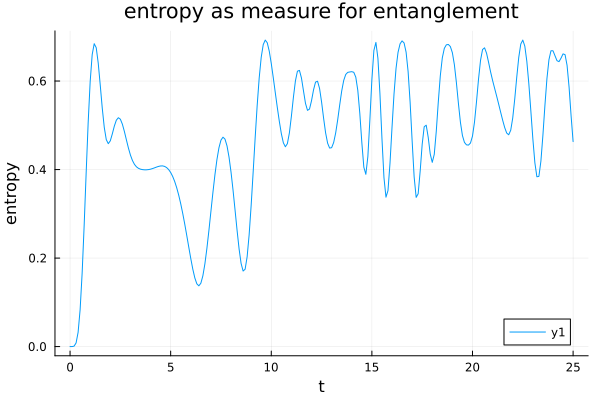

In [39]:
tout, ψent = timeevolution.schroedinger(t2, ψa(2), H_ges);

p_field = [ptrace(ψ, 2) for ψ in ψent];

entropy = [real.(entropy_vn(p)) for p in p_field];

plot(tout, entropy, xlabel="t", ylabel="entropy", title="entropy as measure for entanglement")